<a href="https://colab.research.google.com/github/asrevo-applied-ml/basic-ml/blob/main/e2e_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# End to End machine learning project Full project map


In [1]:
import sys
sys.version # current python version

'3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### EAD

In [3]:
housing_ds=pd.read_csv("https://raw.githubusercontent.com/asrevo-applied-ml/basic-ml/refs/heads/main/housing.csv")
housing_ds.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
housing_ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
housing_ds.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


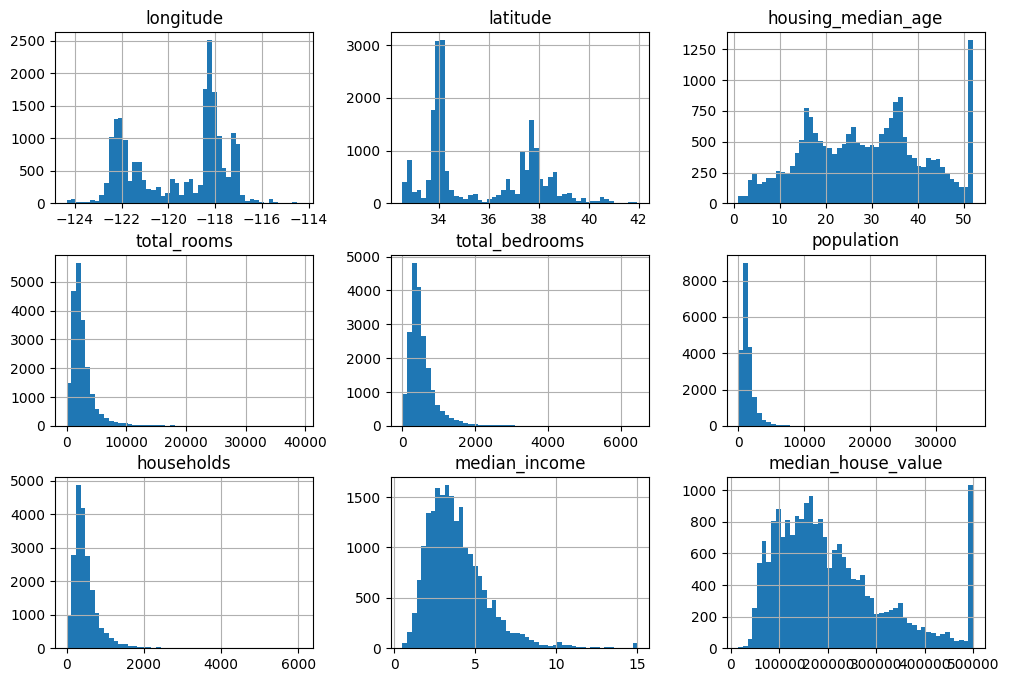

In [6]:

housing_ds.hist(bins=50, figsize=(12, 8))
plt.show()

## Create test data

In [7]:
from sklearn.model_selection import train_test_split
train_ds,test_ds=train_test_split(housing_ds,test_size=.2,random_state=42)

In [8]:
train_ds.shape,test_ds.shape

((16512, 10), (4128, 10))

In [9]:
housing_ds["median_income"].describe()

,median_income
count,20640.000000
mean,3.870671
std,1.899822
min,0.499900
25%,2.563400
50%,3.534800
75%,4.743250
max,15.000100


In [10]:
housing_ds["median_income_cat"]=pd.cut(housing_ds["median_income"],bins=[0., 1.5, 3.0, 4.5, 6., np.inf],labels=[1,2,3,4,5])

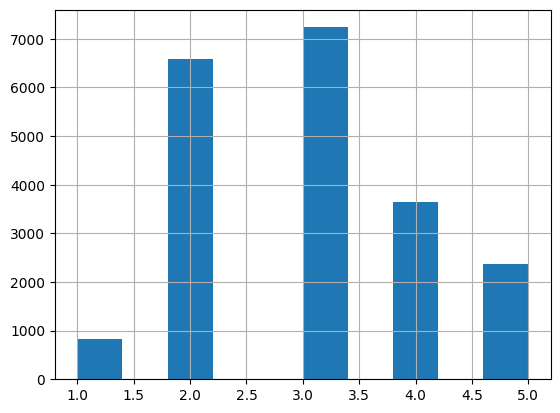

In [11]:
housing_ds["median_income_cat"].hist()
plt.show()

## Split data using strata

In [12]:
strat_train_ds,strat_test_ds=train_test_split(housing_ds,test_size=.2,random_state=42,stratify=housing_ds["median_income_cat"])


## Visualize median_income_cat on both train and test data

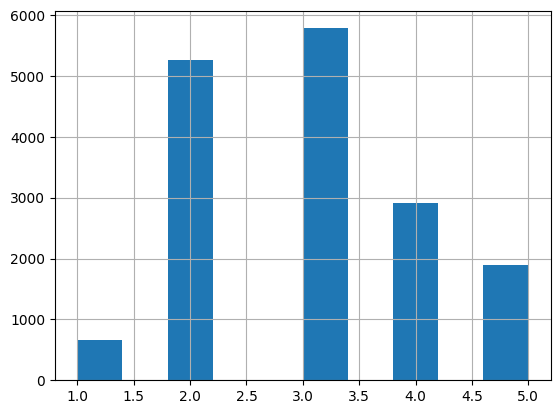

In [13]:
strat_train_ds["median_income_cat"].hist()
plt.show()

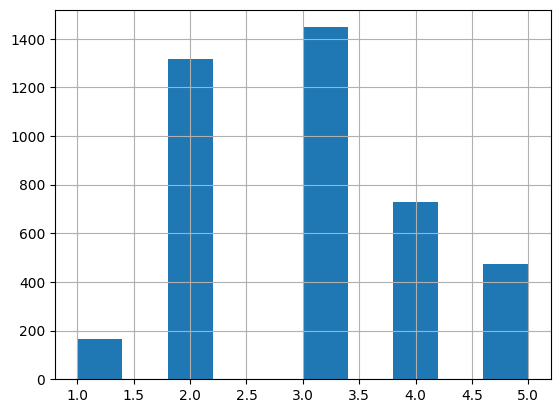

In [14]:
strat_test_ds["median_income_cat"].hist()
plt.show()

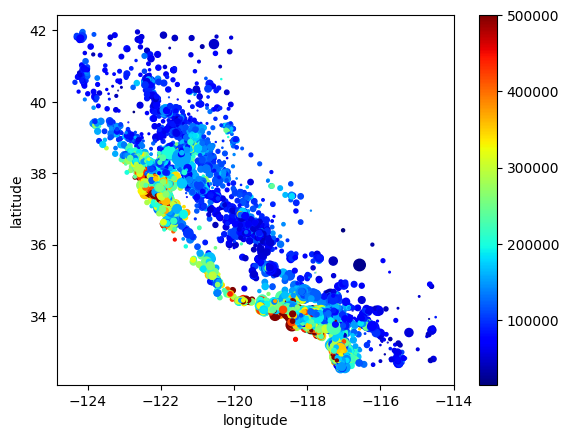

In [15]:
strat_train_ds.plot.scatter(x="longitude",y="latitude",s=strat_train_ds["population"]/100,c=strat_train_ds["median_house_value"],cmap="jet")
plt.show()

## Loking for correlations

In [16]:
strat_train_ds.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 13096 to 19888
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           16512 non-null  float64 
 1   latitude            16512 non-null  float64 
 2   housing_median_age  16512 non-null  float64 
 3   total_rooms         16512 non-null  float64 
 4   total_bedrooms      16344 non-null  float64 
 5   population          16512 non-null  float64 
 6   households          16512 non-null  float64 
 7   median_income       16512 non-null  float64 
 8   median_house_value  16512 non-null  float64 
 9   ocean_proximity     16512 non-null  object  
 10  median_income_cat   16512 non-null  category
dtypes: category(1), float64(9), object(1)
memory usage: 1.4+ MB


In [17]:
col=["housing_median_age","total_rooms","population","median_income","median_house_value"]

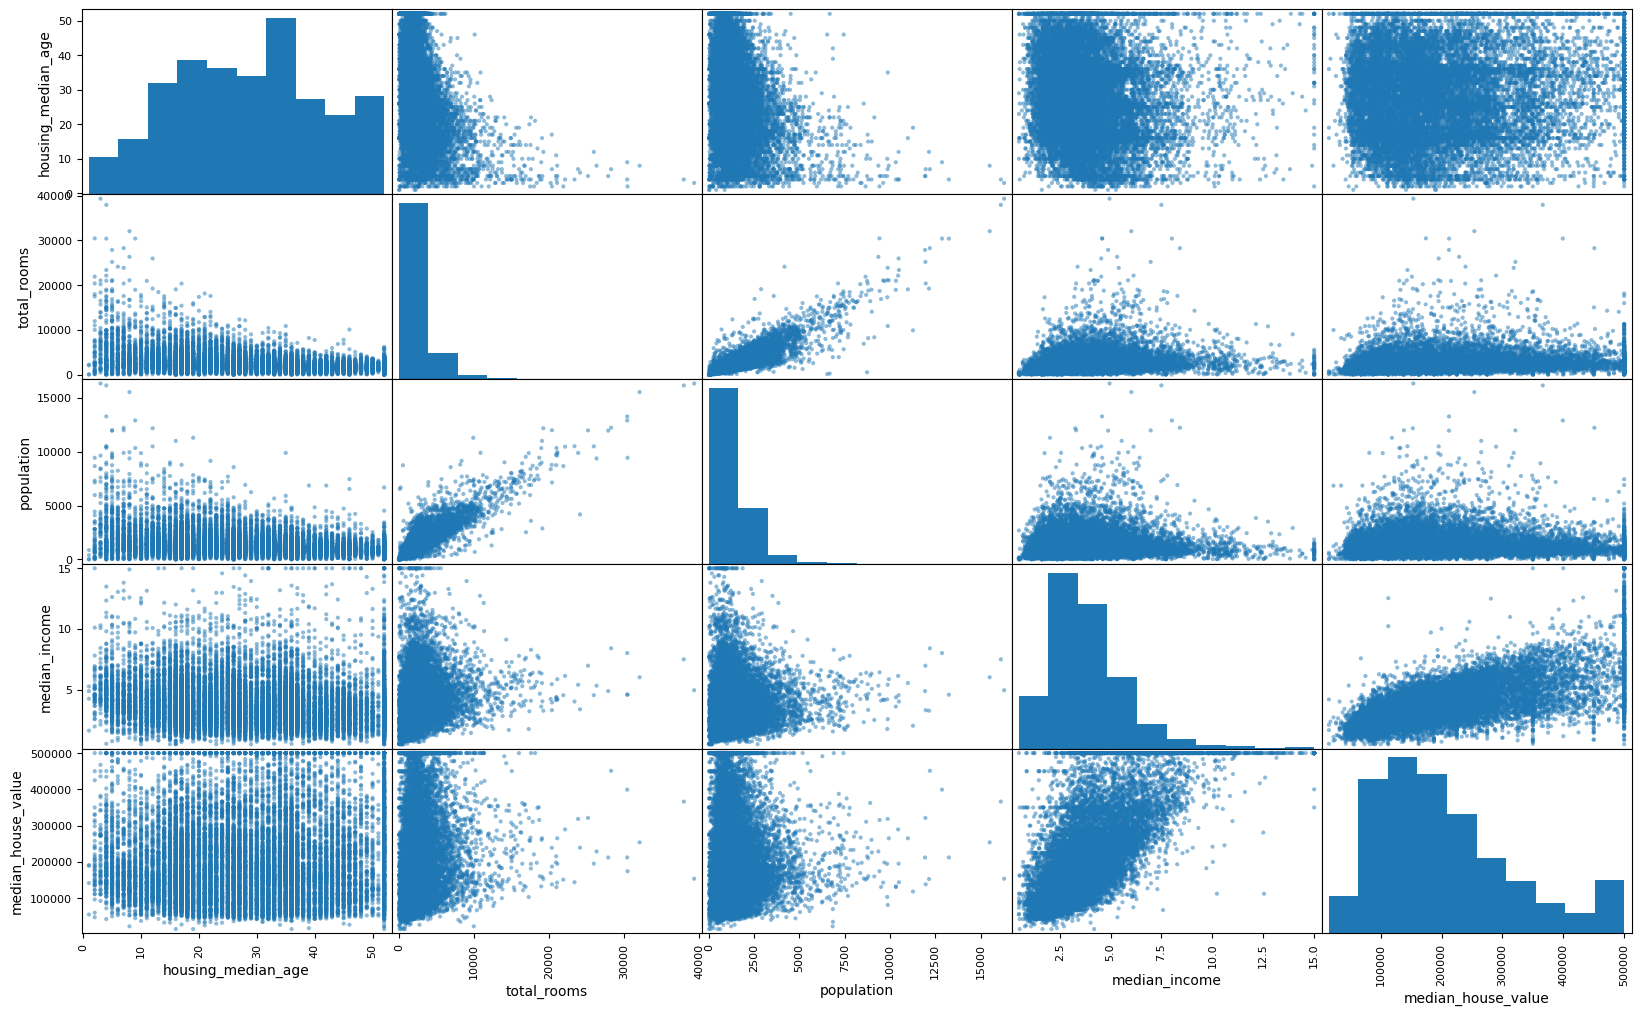

In [18]:
pd.plotting.scatter_matrix(strat_train_ds[col],figsize=(20,12))
plt.show()

In [19]:
strat_train_ds["population"].describe()

,population
count,16512.000000
mean,1425.513929
std,1094.795467
min,3.000000
25%,787.000000
50%,1167.000000
75%,1726.000000
max,16305.000000


array([[<Axes: title={'center': 'population'}>]], dtype=object)

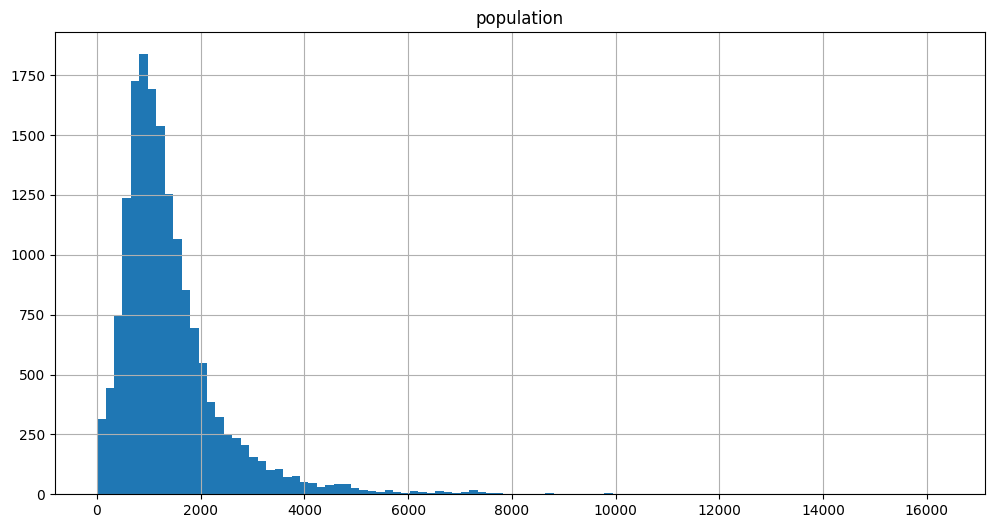

In [20]:
strat_train_ds[["population"]].hist(bins=100,figsize=(12,6))

<Axes: >

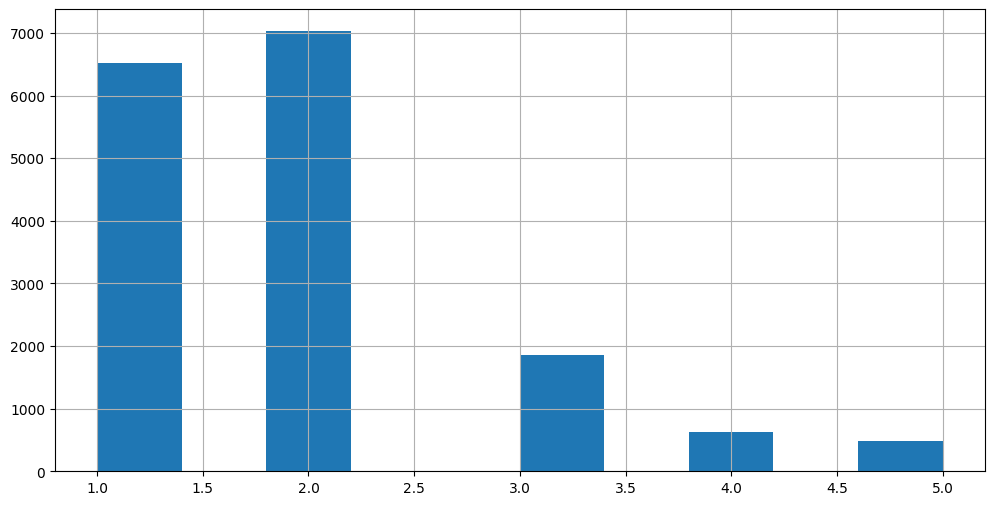

In [21]:
pd.cut(strat_train_ds["population"],bins=[0,1000,2000,3000,4000,np.inf],labels=[1,2,3,4,5]).hist(figsize=(12,6))

In [22]:
strat_train_ds[col].corr()

,housing_median_age,total_rooms,population,median_income,median_house_value
housing_median_age,1.000000,-0.361710,-0.301906,-0.127043,0.102175
total_rooms,-0.361710,1.000000,0.863967,0.197720,0.137455
population,-0.301906,0.863967,1.000000,0.004282,-0.020153
median_income,-0.127043,0.197720,0.004282,1.000000,0.688380
median_house_value,0.102175,0.137455,-0.020153,0.688380,1.000000


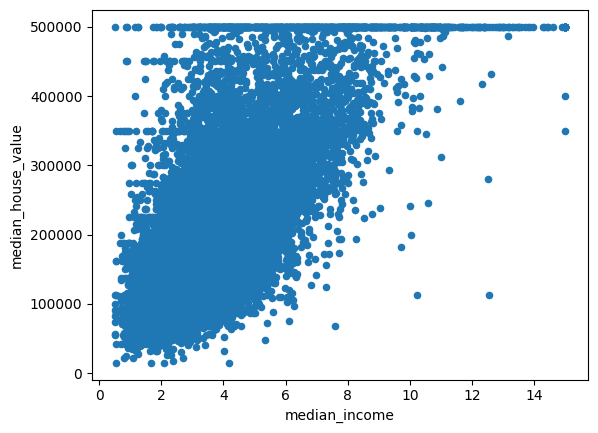

In [23]:
strat_train_ds.plot.scatter(x="median_income",y="median_house_value")
plt.show()

In [24]:
null_indexes=strat_train_ds.isnull().any(axis=1)
print(f"dataset null rows {np.count_nonzero(null_indexes)}")
strat_train_ds.loc[null_indexes]

dataset null rows 168


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,median_income_cat
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,85900.0,INLAND,3
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,150400.0,<1H OCEAN,3
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,161200.0,<1H OCEAN,3
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN,4
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,500001.0,<1H OCEAN,5
...,...,...,...,...,...,...,...,...,...,...,...
2348,-122.70,38.35,14.0,2313.0,NaN,954.0,397.0,3.7813,146500.0,<1H OCEAN,3
366,-122.50,37.75,44.0,1819.0,NaN,1137.0,354.0,3.4919,271800.0,NEAR OCEAN,3
18241,-121.44,38.54,39.0,2855.0,NaN,1217.0,562.0,3.2404,93600.0,INLAND,3
18493,-116.21,33.75,22.0,894.0,NaN,830.0,202.0,3.0673,68200.0,INLAND,3


In [25]:
def seprate_labels(ds=strat_train_ds):
  housing=ds.drop(["median_house_value","median_income_cat"],axis=1).copy()
  housing_labels=ds[["median_house_value"]].copy()
  return housing,housing_labels

In [26]:
housing,housing_labels=seprate_labels()

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,FunctionTransformer
from sklearn.cluster import KMeans

scaler_pipeline=Pipeline([
])

cat_pipeline=Pipeline([
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(sparse_output=False)),
])

log_pipeline=Pipeline([
    ("impute",SimpleImputer(strategy="mean")),
    ("log",FunctionTransformer(np.log,feature_names_out="one-to-one")),
   ("scaler",StandardScaler())
])





In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import rbf_kernel
c=KMeans()
c.fit(housing[["longitude","latitude"]])



d=rbf_kernel(housing[["longitude","latitude"]], c.cluster_centers_)
housing[["longitude","latitude"]].shape,c.cluster_centers_.shape,d.shape,

((16512, 2), (8, 2), (16512, 8))

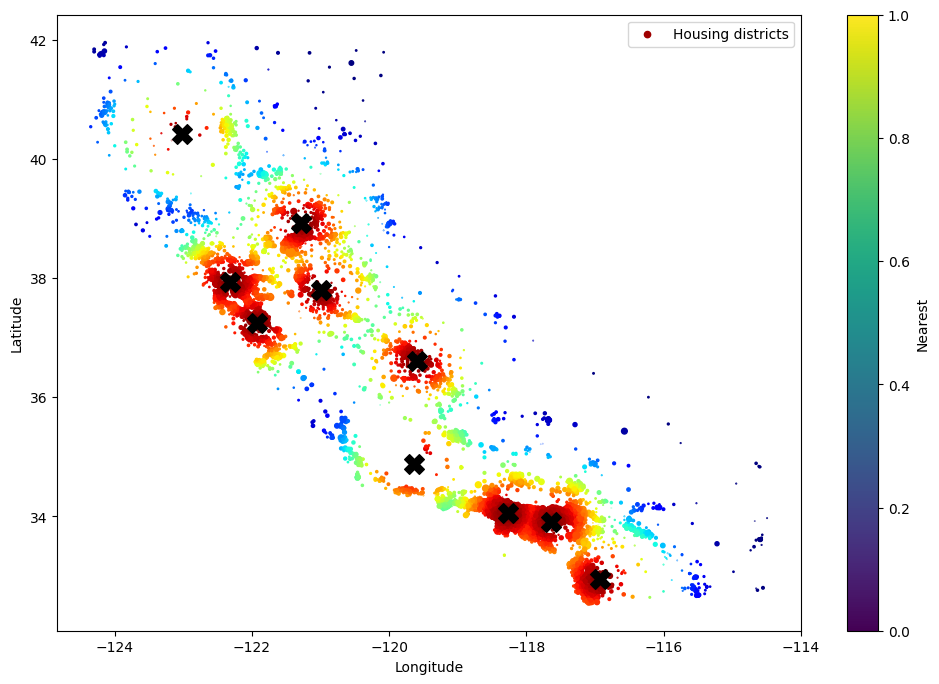

In [29]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import rbf_kernel

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, n_init=10,
                              random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)


similarities=cluster_simil.fit_transform(housing[["longitude","latitude"]])
pd.DataFrame(similarities,columns=cluster_simil.get_feature_names_out())
centers=cluster_simil.kmeans_.cluster_centers_

plt.figure(figsize=(12, 8))
plt.scatter(x=housing["longitude"],y=housing["latitude"],marker=".",s=housing["population"]/100,c=similarities.max(axis=1),cmap="jet", label="Housing districts")
plt.scatter(x=centers[:,0],y=centers[:,1],marker="X",c="black",s=200)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Nearest")
plt.legend(loc="upper right")

plt.show()


## Testing Pipeline

In [30]:
from sklearn.compose import ColumnTransformer


transformer=ColumnTransformer(
    [
        ("1",log_pipeline,["housing_median_age",	"total_rooms",	"total_bedrooms",	"population",	"households",	"median_income"]),
        ("2",cat_pipeline,["ocean_proximity"]),
        ("3",cluster_simil,["longitude","latitude"]),
    ]
    ,remainder="passthrough"
)

In [31]:
# transformed=transformer.fit_transform(housing)
# transformed_names=transformer.get_feature_names_out()
# transformed_housing=pd.DataFrame(transformed,columns=transformed_names)
# transformed_housing


In [32]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import root_mean_squared_error

def evaluate(pipeline,cv:int=3,x=housing,y=housing_labels):
  pipeline.fit(x,y)
  housing_predicted_label=pipeline.predict(x)
  error=root_mean_squared_error(y,housing_predicted_label)
  print(f"error = {error}")
  tree_rmses = -cross_val_score(pipeline, x, y,
                              scoring="neg_root_mean_squared_error", cv=cv)
  return pd.Series(tree_rmses).describe()



In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression


pipeline=Pipeline([("transformer",transformer),("model",LinearRegression())])
evaluate(pipeline)

error = 69619.479073167


,0
count,3.000000
mean,69903.171058
std,764.101880
min,69245.450714
25%,69484.082060
50%,69722.713405
75%,70232.031229
max,70741.349053


In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pipeline=Pipeline([("transformer",transformer),("model",TransformedTargetRegressor(regressor=LinearRegression(),transformer=FunctionTransformer(func=np.log,inverse_func=np.exp)))])
evaluate(pipeline)


error = 65360.8481097404


,0
count,3.000000
mean,65512.936858
std,927.955243
min,64464.194776
25%,65155.612010
50%,65847.029245
75%,66037.307900
max,66227.586554


In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import root_mean_squared_error

pipeline=Pipeline([("transformer",transformer),("model",TransformedTargetRegressor(regressor=DecisionTreeRegressor(),transformer=FunctionTransformer(func=np.log,inverse_func=np.exp)))])
evaluate(pipeline)


error = 1.5662974201132387e-10


,0
count,3.000000
mean,66963.509086
std,1712.360090
min,65915.469379
25%,65975.484927
50%,66035.500476
75%,67487.528939
max,68939.557402


In [36]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import root_mean_squared_error

pipeline=Pipeline([("transformer",transformer),("model",TransformedTargetRegressor(regressor=RandomForestRegressor(n_estimators=20),transformer=FunctionTransformer(func=np.log,inverse_func=np.exp)))])
evaluate(pipeline)

error = 20852.286020697113


,0
count,3.000000
mean,50007.097641
std,719.450435
min,49381.705574
25%,49613.962536
50%,49846.219498
75%,50319.793674
max,50793.367851


In [37]:
from sklearn.model_selection import GridSearchCV

grid=GridSearchCV(estimator=pipeline,param_grid={"model__regressor__n_estimators":[3,5,7,10],"transformer__3__n_clusters":[3,5,7,10,12,15]},cv=3,scoring="neg_root_mean_squared_error")
grid.fit(housing, housing_labels)


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('transformer',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('1',
                                                                         Pipeline(steps=[('impute',
                                                                                          SimpleImputer()),
                                                                                         ('log',
                                                                                          FunctionTransformer(feature_names_out='one-to-one',
                                                                                                              func=<ufunc 'log'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['housing_median_age',
                                                                          'total_rooms',
                                                                          'total_bedrooms',
                                                                          'population',
                                                                          'households',...
                                                                         ClusterSimilarity(random_state=42),
                                                                         ['longitude',
                                                                          'latitude'])])),
                                       ('model',
                                        TransformedTargetRegressor(regressor=RandomForestRegressor(n_estimators=20),
                                                                   transformer=FunctionTransformer(func=<ufunc 'log'>,
                                                                                                   inverse_func=<ufunc 'exp'>)))]),
             param_grid={'model__regressor__n_estimators': [3, 5, 7, 10],
                         'transformer__3__n_clusters': [3, 5, 7, 10, 12, 15]},
             scoring='neg_root_mean_squared_error')

In [38]:
grid

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('transformer',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('1',
                                                                         Pipeline(steps=[('impute',
                                                                                          SimpleImputer()),
                                                                                         ('log',
                                                                                          FunctionTransformer(feature_names_out='one-to-one',
                                                                                                              func=<ufunc 'log'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['housing_median_age',
                                                                          'total_rooms',
                                                                          'total_bedrooms',
                                                                          'population',
                                                                          'households',...
                                                                         ClusterSimilarity(random_state=42),
                                                                         ['longitude',
                                                                          'latitude'])])),
                                       ('model',
                                        TransformedTargetRegressor(regressor=RandomForestRegressor(n_estimators=20),
                                                                   transformer=FunctionTransformer(func=<ufunc 'log'>,
                                                                                                   inverse_func=<ufunc 'exp'>)))]),
             param_grid={'model__regressor__n_estimators': [3, 5, 7, 10],
                         'transformer__3__n_clusters': [3, 5, 7, 10, 12, 15]},
             scoring='neg_root_mean_squared_error')

In [39]:
grid.best_params_,grid.best_score_

({'model__regressor__n_estimators': 10, 'transformer__3__n_clusters': 15},
 np.float64(-50677.71698814799))

In [40]:
evaluate(grid.best_estimator_)

error = 21628.345904077993


,0
count,3.000000
mean,50603.409814
std,281.142097
min,50439.096615
25%,50441.096455
50%,50443.096294
75%,50685.566413
max,50928.036532


In [41]:
housing_test,housing_test_labels=seprate_labels(strat_test_ds)
housing_predict_test=grid.best_estimator_.predict(housing_test )
root_mean_squared_error(housing_test_labels,housing_predict_test)

50407.87805978666

## Exercise

In [44]:
from sklearn.svm import SVR

pipeline=Pipeline([("transformer",transformer),("model",TransformedTargetRegressor(regressor=SVR(),transformer=FunctionTransformer(func=np.log,inverse_func=np.exp)))])
evaluate(pipeline)

error = 50056.0862924676


,0
count,3.000000
mean,53813.676522
std,1249.973595
min,52555.937105
25%,53192.646390
50%,53829.355674
75%,54442.546230
max,55055.736787


In [ ]:
grid=GridSearchCV(estimator=pipeline,param_grid={"transformer__3__n_clusters":[3,5,7,10,15],"model__regressor__kernel":["rbf","linear"],"model__regressor__C":[10., 30., 100., 300., 1000.,
                                               3000., 10000., 30000.0]},cv=3,scoring="neg_root_mean_squared_error")
grid.fit(housing,housing_labels)

In [47]:
evaluate(grid.best_estimator_)

error = 49604.26772216847


,0
count,3.000000
mean,53406.785438
std,1299.112568
min,52085.525795
25%,52768.900136
50%,53452.274477
75%,54067.415259
max,54682.556041


In [48]:
grid.best_params_

{'model__regressor__kernel': 'rbf', 'transformer__3__n_clusters': 15}